In [1]:
import os
import numpy as np
import pandas as pd

CSV = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "articles_sampled.csv" in files:
        CSV = os.path.join(root, "articles_sampled.csv")
        break

BASE = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "articles.csv" in files:
        BASE = root
        break

print("sample csv:", CSV)
print("data folder:", BASE)

df = pd.read_csv(CSV, dtype={"article_id": str})
print("images in file:", len(df))

sample csv: /kaggle/input/datasets/khaledmahmoud202/team-images/articles_sampled.csv
data folder: /kaggle/input/competitions/h-and-m-personalized-fashion-recommendations
images in file: 30000


In [2]:
import shutil
from PIL import Image

OUT = "/kaggle/working/sampled_images"
os.makedirs(OUT, exist_ok=True)

copied, missing = 0, []
for n, a in enumerate(df["article_id"]):
    src = f"{BASE}/images/{a[:3]}/{a}.jpg"
    if os.path.exists(src):
        img = Image.open(src).convert("RGB")
        img.thumbnail((256, 256))
        img.save(f"{OUT}/{a}.jpg", quality=90)
        copied += 1
    else:
        missing.append(a)
    if n % 5000 == 0:
        print("done:", n, "/", len(df))

print("copied:", copied, "| missing:", len(missing))

shutil.make_archive("/kaggle/working/sampled_images", "zip", OUT)
print("zip size MB:", round(os.path.getsize("/kaggle/working/sampled_images.zip") / 1e6))

done: 0 / 30000
done: 5000 / 30000
done: 10000 / 30000
done: 15000 / 30000
done: 20000 / 30000
done: 25000 / 30000
copied: 30000 | missing: 0
zip size MB: 213


In [3]:
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

ids = df["article_id"].tolist()

tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class Imgs(Dataset):
    def __len__(self):
        return len(ids)
    def __getitem__(self, i):
        a = ids[i]
        try:
            x = tf(Image.open(f"{BASE}/images/{a[:3]}/{a}.jpg").convert("RGB"))
            return x, i, True
        except:
            return torch.zeros(3, 224, 224), i, False

loader = DataLoader(Imgs(), batch_size=64, num_workers=4)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

model = models.resnet50(weights="IMAGENET1K_V2")
model.fc = torch.nn.Identity()
model = model.to(device).eval()

all_emb, all_ids = [], []
for n, (x, idx, ok) in enumerate(loader):
    with torch.no_grad():
        e = model(x.to(device)).cpu().numpy()
    ok = ok.numpy()
    all_emb.append(e[ok])
    all_ids += [ids[i] for i in idx.numpy()[ok]]
    if n % 50 == 0:
        print("done:", n * 64, "/", len(ids))

np.save("emb_resnet.npy", np.vstack(all_emb))
pd.Series(all_ids, name="article_id").to_csv("ids_resnet.csv", index=False)
print("finished, images:", len(all_ids))

device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 164MB/s] 


done: 0 / 30000
done: 3200 / 30000
done: 6400 / 30000
done: 9600 / 30000
done: 12800 / 30000
done: 16000 / 30000
done: 19200 / 30000
done: 22400 / 30000
done: 25600 / 30000
done: 28800 / 30000
finished, images: 30000


In [5]:
from transformers import CLIPModel, CLIPProcessor

device = "cuda"
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).half().eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

class ImgsClip(Dataset):
    def __len__(self):
        return len(ids)
    def __getitem__(self, i):
        a = ids[i]
        try:
            img = Image.open(f"{BASE}/images/{a[:3]}/{a}.jpg").convert("RGB")
            x = proc(images=img, return_tensors="pt")["pixel_values"][0]
            return x, i, True
        except:
            return torch.zeros(3, 224, 224), i, False

loader = DataLoader(ImgsClip(), batch_size=128, num_workers=4)

def clip_embed(pixel_values):
    out = clip.vision_model(pixel_values=pixel_values)
    return clip.visual_projection(out.pooler_output)

all_emb, all_ids = [], []
for n, (x, idx, ok) in enumerate(loader):
    with torch.no_grad():
        e = clip_embed(x.to(device).half()).float().cpu().numpy()
    ok = ok.numpy()
    all_emb.append(e[ok])
    all_ids += [ids[i] for i in idx.numpy()[ok]]
    if n % 50 == 0:
        print("done:", n * 128, "/", len(ids), "| shape:", e.shape)

np.save("emb_clip.npy", np.vstack(all_emb))
pd.Series(all_ids, name="article_id").to_csv("ids_clip.csv", index=False)
print("finished, images:", len(all_ids))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

done: 0 / 30000 | shape: (128, 512)
done: 6400 / 30000 | shape: (128, 512)
done: 12800 / 30000 | shape: (128, 512)
done: 19200 / 30000 | shape: (128, 512)
done: 25600 / 30000 | shape: (128, 512)
finished, images: 30000


In [6]:
from sklearn.metrics.pairwise import cosine_similarity

meta = df.set_index("article_id")

def load_emb(name):
    e = np.load(f"emb_{name}.npy")
    i = pd.read_csv(f"ids_{name}.csv", dtype={"article_id": str})["article_id"].tolist()
    return e, i

emb, ids = load_emb("clip")
print("embeddings shape:", emb.shape)

sim = cosine_similarity(emb[:1], emb)[0]
top = np.argsort(-sim)[1:11]
print("item:", ids[0])
print("most similar:", [ids[i] for i in top])

embeddings shape: (30000, 512)
item: 0667999002
most similar: ['0575522006', '0805931002', '0622877001', '0678756002', '0375248010', '0842064001', '0712104002', '0797866003', '0698867001', '0379360034']


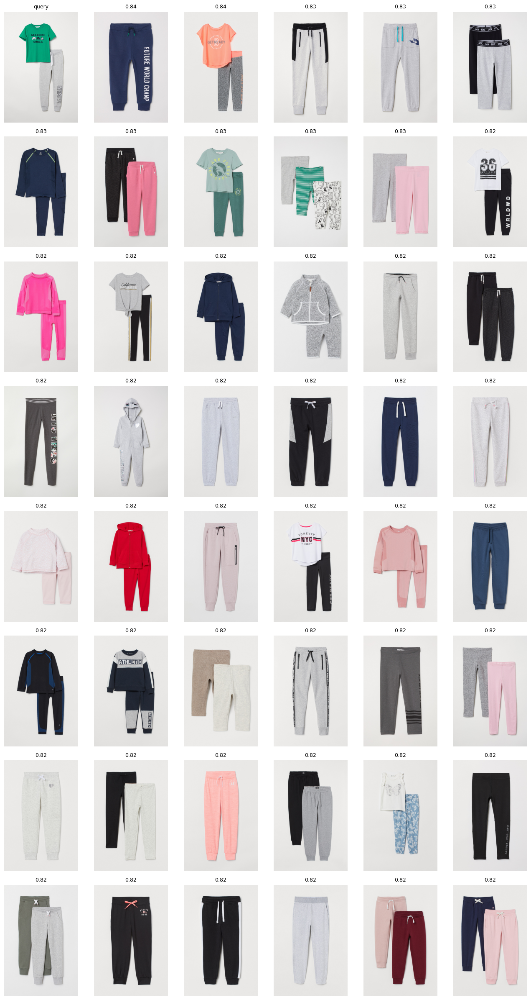

In [7]:
import matplotlib.pyplot as plt

def show_similar(idx, k=47, cols=6):
    sim = cosine_similarity(emb[idx:idx+1], emb)[0]
    top = np.argsort(-sim)[:k+1]

    rows = (len(top) + cols - 1) // cols
    plt.figure(figsize=(2.2*cols, 3*rows))
    for j, t in enumerate(top):
        a = ids[t]
        img = Image.open(f"{BASE}/images/{a[:3]}/{a}.jpg")
        plt.subplot(rows, cols, j+1)
        plt.imshow(img)
        plt.axis("off")
        plt.title("query" if j == 0 else f"{sim[t]:.2f}", fontsize=9)
    plt.tight_layout()
    plt.show()

show_similar(0, k=47)

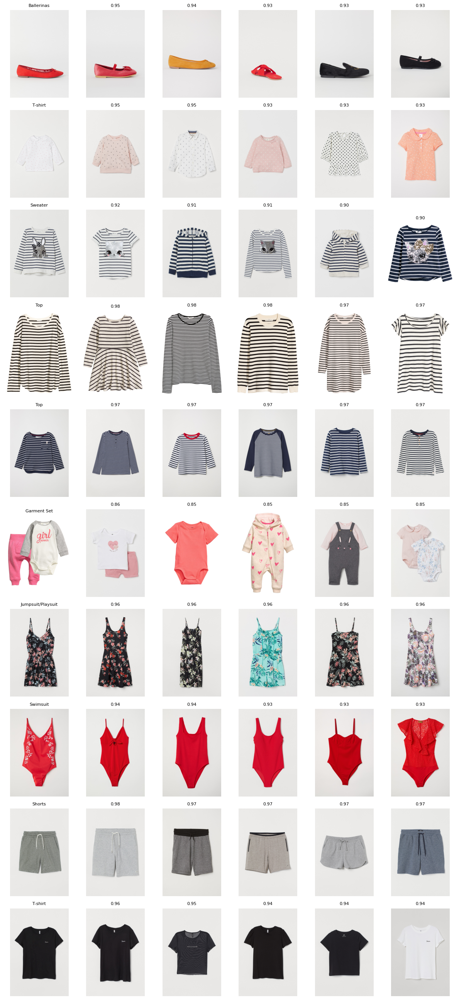

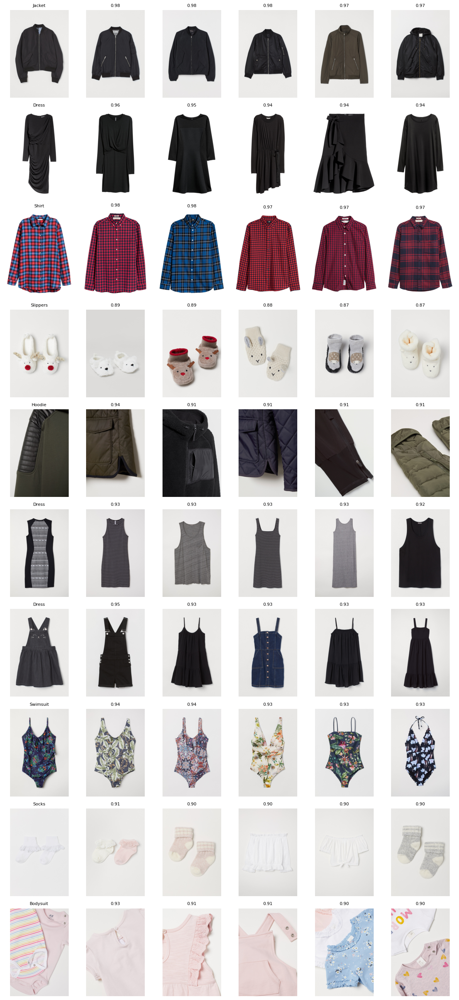

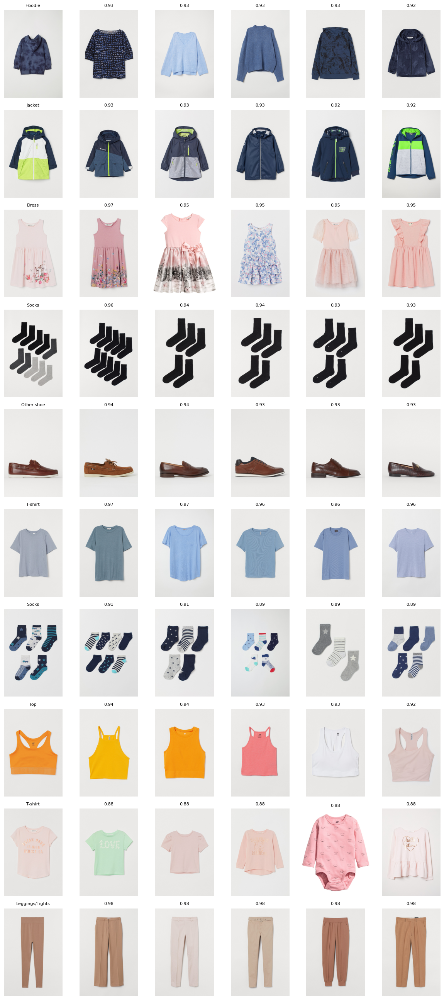

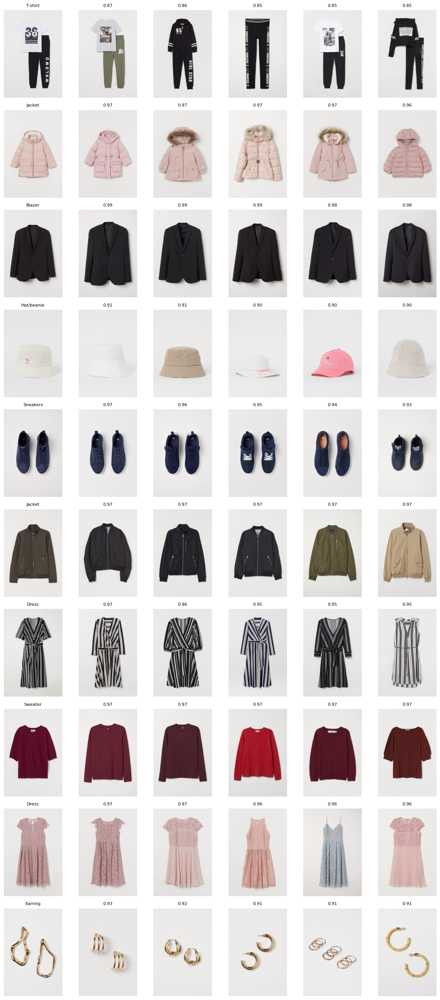

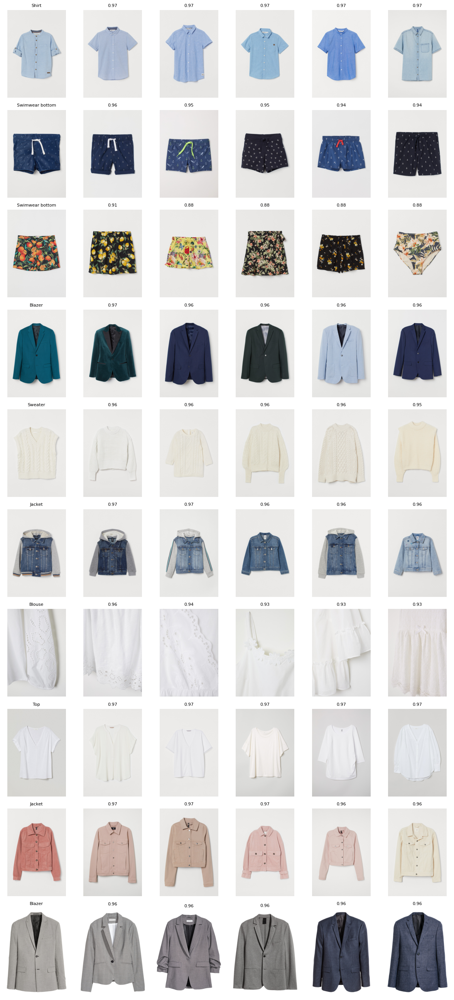

In [8]:
types = meta.loc[ids, "product_type_name"].values

candidates = np.where(types != "Trousers")[0]
picked = np.random.default_rng(1).choice(candidates, 50, replace=False)

def show_rows(query_list, k=5):
    rows = len(query_list)
    plt.figure(figsize=(2*(k+1), 2.6*rows))
    for r, q in enumerate(query_list):
        sim = cosine_similarity(emb[q:q+1], emb)[0]
        top = np.argsort(-sim)[:k+1]
        for c, t in enumerate(top):
            a = ids[t]
            img = Image.open(f"{BASE}/images/{a[:3]}/{a}.jpg")
            plt.subplot(rows, k+1, r*(k+1) + c + 1)
            plt.imshow(img)
            plt.axis("off")
            plt.title(types[q] if c == 0 else f"{sim[t]:.2f}", fontsize=8)
    plt.tight_layout()
    plt.show()

for i in range(0, 50, 10):
    show_rows(picked[i:i+10])

In [11]:
def match_rate(emb, ids, col, k=10, n=1000):
    labels = meta.loc[ids, col].values
    emb = emb / np.linalg.norm(emb, axis=1, keepdims=True)
    q_idx = np.random.default_rng(0).choice(len(ids), n, replace=False)

    sim = emb[q_idx] @ emb.T
    top = np.argsort(-sim, axis=1)[:, 1:k+1]

    hits = (labels[top] == labels[q_idx][:, None]).mean(axis=1)
    return round(hits.mean(), 3)

cols = ["product_group_name", "product_type_name", "colour_group_name"]

for name in ["resnet", "clip"]:
    e, i = load_emb(name)
    print(name, dict(zip(cols, [match_rate(e, i, c) for c in cols])))

for c in cols:
    p = meta[c].value_counts(normalize=True)
    print(c, "random baseline:", round((p**2).sum(), 3))

resnet {'product_group_name': np.float64(0.867), 'product_type_name': np.float64(0.609), 'colour_group_name': np.float64(0.321)}
clip {'product_group_name': np.float64(0.874), 'product_type_name': np.float64(0.628), 'colour_group_name': np.float64(0.409)}
product_group_name random baseline: 0.269
product_type_name random baseline: 0.053
colour_group_name random baseline: 0.082


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

for name in ["resnet", "clip"]:
    e, i = load_emb(name)
    e = e / np.linalg.norm(e, axis=1, keepdims=True)
    for col in ["product_type_name", "colour_group_name"]:
        y = meta.loc[i, col].values
        Xtr, Xte, ytr, yte = train_test_split(e, y, test_size=0.2, random_state=42)
        clf = LogisticRegression(max_iter=300).fit(Xtr, ytr)
        print(name, col, "accuracy:", round(clf.score(Xte, yte), 3))

resnet product_type_name accuracy: 0.701
resnet colour_group_name accuracy: 0.552
clip product_type_name accuracy: 0.707
clip colour_group_name accuracy: 0.632


In [13]:
e, i = load_emb("clip")
e = e / np.linalg.norm(e, axis=1, keepdims=True)
id2row = {a: r for r, a in enumerate(i)}

tx = pd.read_csv(BASE + "/transactions_train.csv",
                 usecols=["t_dat", "customer_id", "article_id"],
                 dtype={"article_id": str})
tx = tx[tx["article_id"].isin(id2row)]
tx["t_dat"] = pd.to_datetime(tx["t_dat"])

split = tx["t_dat"].max() - pd.Timedelta(days=7)
train = tx[tx["t_dat"] <= split]
test = tx[tx["t_dat"] > split]

recent = train[train["t_dat"] > split - pd.Timedelta(days=28)]
pop = recent["article_id"].value_counts()
pop_vec = np.zeros(len(i))
for a, c in pop.items():
    pop_vec[id2row[a]] = c
pop_vec = pop_vec / pop_vec.max()
pop_top = np.argsort(-pop_vec)[:12]

bought = train.sort_values("t_dat").groupby("customer_id")["article_id"].apply(list)
future = test.groupby("customer_id")["article_id"].apply(set)
users = [u for u in future.index if u in bought.index]
users = np.random.default_rng(0).choice(users, min(3000, len(users)), replace=False)

def recall_at_12(get_top):
    r = []
    for u in users:
        top = {i[t] for t in get_top(u)}
        r.append(len(top & future[u]) / len(future[u]))
    return round(np.mean(r), 4)

def visual_scores(u):
    rows = [id2row[a] for a in bought[u][-20:] if a in id2row]
    if len(rows) == 0:
        return np.zeros(len(i))
    return e @ e[rows].mean(0)

print("popular:", recall_at_12(lambda u: pop_top))
print("visual:", recall_at_12(lambda u: np.argsort(-visual_scores(u))[:12]))

for alpha in [0.5, 1, 2]:
    print("hybrid", alpha, ":",
          recall_at_12(lambda u: np.argsort(-(pop_vec + alpha * visual_scores(u)))[:12]))

popular: 0.0578
visual: 0.011
hybrid 0.5 : 0.0578
hybrid 1 : 0.0584
hybrid 2 : 0.0611


In [14]:
users = [u for u in future.index if u in bought.index]
users = np.random.default_rng(0).choice(users, min(10000, len(users)), replace=False)

def scaled_visual(u):
    s = visual_scores(u)
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

def per_user_recall(get_top):
    r = []
    for u in users:
        top = {i[t] for t in get_top(u)}
        r.append(len(top & future[u]) / len(future[u]))
    return np.array(r)

r_pop = per_user_recall(lambda u: pop_top)
print("popular:", round(r_pop.mean(), 4))

def compare(r_new, r_base, n_boot=2000):
    diff = r_new - r_base
    rng = np.random.default_rng(0)
    boots = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(n_boot)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return round(diff.mean(), 4), round(lo, 4), round(hi, 4)

for alpha in [0.5, 1, 2, 4, 8]:
    r_h = per_user_recall(lambda u: np.argsort(-(pop_vec + alpha * scaled_visual(u)))[:12])
    print("hybrid", alpha, "recall:", round(r_h.mean(), 4), "| diff, ci low, ci high:", compare(r_h, r_pop))

popular: 0.0553
hybrid 0.5 recall: 0.0565 | diff, ci low, ci high: (np.float64(0.0011), np.float64(-0.0003), np.float64(0.0026))
hybrid 1 recall: 0.0593 | diff, ci low, ci high: (np.float64(0.0039), np.float64(0.0018), np.float64(0.0061))
hybrid 2 recall: 0.0638 | diff, ci low, ci high: (np.float64(0.0084), np.float64(0.0056), np.float64(0.0113))
hybrid 4 recall: 0.0648 | diff, ci low, ci high: (np.float64(0.0095), np.float64(0.0059), np.float64(0.0134))
hybrid 8 recall: 0.0522 | diff, ci low, ci high: (np.float64(-0.0031), np.float64(-0.0078), np.float64(0.0013))


In [15]:
rng = np.random.default_rng(5)
perm = rng.permutation(len(users))
users_a = users[perm[:len(users)//2]]
users_b = users[perm[len(users)//2:]]

def per_user_recall_on(user_list, get_top):
    r = []
    for u in user_list:
        top = {i[t] for t in get_top(u)}
        r.append(len(top & future[u]) / len(future[u]))
    return np.array(r)

best_alpha, best_score = None, -1
for alpha in [1, 2, 4, 6]:
    s = per_user_recall_on(users_a, lambda u: np.argsort(-(pop_vec + alpha * scaled_visual(u)))[:12]).mean()
    print("alpha", alpha, "on set A:", round(s, 4))
    if s > best_score:
        best_alpha, best_score = alpha, s

print("chosen alpha:", best_alpha)

r_pop_b = per_user_recall_on(users_b, lambda u: pop_top)
r_hyb_b = per_user_recall_on(users_b, lambda u: np.argsort(-(pop_vec + best_alpha * scaled_visual(u)))[:12])
print("set B popular:", round(r_pop_b.mean(), 4), "| hybrid:", round(r_hyb_b.mean(), 4))
print("diff, ci low, ci high:", compare(r_hyb_b, r_pop_b))

alpha 1 on set A: 0.0571
alpha 2 on set A: 0.0611
alpha 4 on set A: 0.0628
alpha 6 on set A: 0.0589
chosen alpha: 4
set B popular: 0.0549 | hybrid: 0.0668
diff, ci low, ci high: (np.float64(0.0119), np.float64(0.0066), np.float64(0.0173))
